In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [2]:
# Load Dataset

df = pd.read_csv(
    "diabetic_data.csv",
    na_values="?",
    low_memory=False
)

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully
Dataset Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# data information chevking
df.info()
# printinging on Dataset Shape
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [7]:
#checking for missing values & correcting the Missing Values
missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

missing_values

#working on Missing Value Percentage

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

missing_percentage



weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

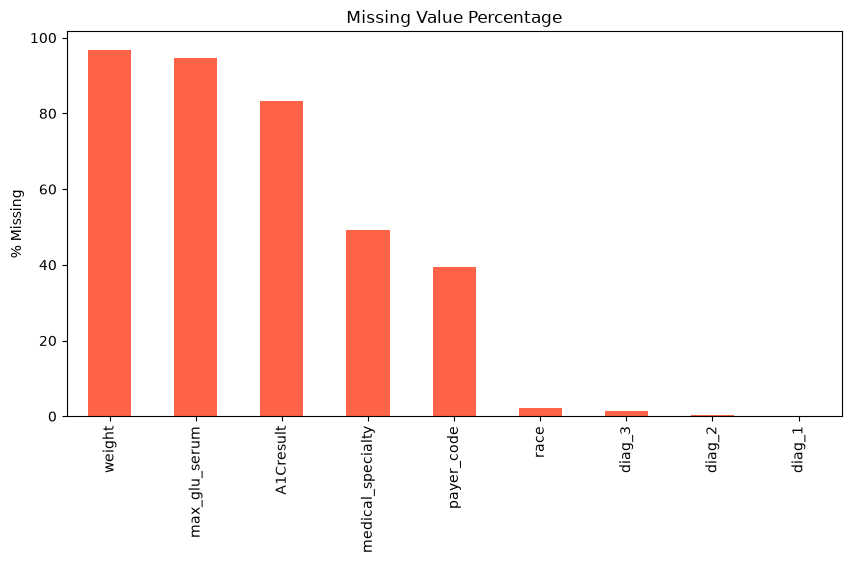

In [8]:
# printing Missing Values Graph
plt.figure(figsize=(10, 5))

missing_percentage.plot(
    kind="bar",
    color="tomato"
)

plt.title("Missing Value Percentage")
plt.ylabel("% Missing")

plt.show()

In [ ]:
# checking for any Duplicate values

duplicates = df.duplicated().sum()
print("Duplicate Rows:", duplicates)

# Target Variable Analysis from the data set
df["readmitted"].value_counts()

Duplicate Rows: 0


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

C:\Users\lavan\AppData\Local\Temp\ipykernel_29352\3571084459.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


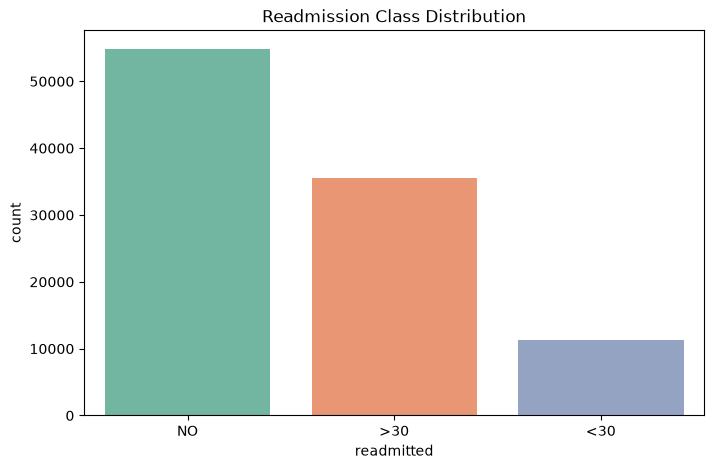

In [11]:
#Class Distribution Graph

plt.figure(figsize=(8,5))

sns.countplot(
    x="readmitted",
    data=df,
    palette="Set2"
)

plt.title("Readmission Class Distribution")

plt.show()

In [12]:
#Class Imbalance Ratio:
counts = df["readmitted"].value_counts()

ratio = counts.max() / counts.min()

print("Imbalance Ratio:", round(ratio, 2))

Imbalance Ratio: 4.83


In [15]:
#working on the Feature Types
categorical_cols = df.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:", len(categorical_cols))
print("Numerical Features:", len(numerical_cols))

Categorical Features: 37
Numerical Features: 13


C:\Users\lavan\AppData\Local\Temp\ipykernel_29352\1652300908.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


Phase 2: Data Preprocessing

In [16]:
#Defining Features and Target - to Separate predictors (X) from the target (y).

# =====================================
# FEATURES AND TARGET
# =====================================

target = "readmitted"
X = df.drop(columns=[target])
y = df[target]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (101766, 49)
Target Shape: (101766,)


In [17]:
# we are removing Identifier Columns as these columns do not help prediction. (encounter_id ,patient_nbr)
# =====================================
# REMOVE ID COLUMNS
# =====================================

id_columns = [
    "encounter_id",
    "patient_nbr"
]
X = X.drop(columns=id_columns)
print("Shape After Removing IDs:")
print(X.shape)

Shape After Removing IDs:
(101766, 47)


In [18]:
#Training -Test Split (80:20) as per ou
#Assignment Requirement we need to ahve (- 80:20 split, Random seed, Maintain class distribution)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (81412, 47)
Testing Shape: (20354, 47)


In [19]:
#Verifying Class Distribution - as our assignemnt asked to maintain class distribution.
print("Original Distribution")
print(    y.value_counts(normalize=True))
print("\nTraining Distribution")
print(    y_train.value_counts(normalize=True))
print("\nTesting Distribution")
print(    y_test.value_counts(normalize=True))

Original Distribution
readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64

Training Distribution
readmitted
NO     0.539122
>30    0.349285
<30    0.111593
Name: proportion, dtype: float64

Testing Distribution
readmitted
NO     0.539108
>30    0.349268
<30    0.111624
Name: proportion, dtype: float64


In [20]:
#Now we are Identifying Feature Types
#Different preprocessing for: Numerical columns, Categorical columns
import numpy as np
categorical_features = (
    X_train
    .select_dtypes(
        include=["object"]
    )
    .columns
    .tolist()
)
numerical_features = (
    X_train
    .select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)
print("Categorical Features:", len(categorical_features))
print("Numerical Features:", len(numerical_features))

Categorical Features: 36
Numerical Features: 11


C:\Users\lavan\AppData\Local\Temp\ipykernel_29352\2500866111.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(


In [21]:
#we are going to Import Preprocessing Classes
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [22]:
#Verifying on Numerical Pipeline -As some numerical features may have missing values. 
#We'll check Impute median, Scale using StandardScaler

numeric_transformer = Pipeline(
    steps=[ ( "imputer",
            SimpleImputer(
                strategy="median"   )   ),
        ( "scaler",
            StandardScaler()
        )   ] )

In [23]:
# Now on Categorical Pipeline. As Machine Learning models cannot understand text.
#We'll be Fill missing categories, One-Hot Encoding
categorical_transformer = Pipeline(
    steps=[( "imputer",
            SimpleImputer( strategy="most_frequent")  ),
        ( "encoder",
            OneHotEncoder(handle_unknown="ignore" ) ) ]
)

In [24]:
#Here we are Combining Both Pipelines (Numerical & categorical)
preprocessor = ColumnTransformer(
    transformers=[ ( "num",
            numeric_transformer,
            numerical_features),
        ( "cat",
            categorical_transformer,
            categorical_features ) ]
)
print("Preprocessor Created Successfully")

Preprocessor Created Successfully


In [25]:
#In Here Now We are Testing the Pipeline to check and ensuring preprocessing works before model training.
X_train_processed = preprocessor.fit_transform(    X_train)
X_test_processed = preprocessor.transform( X_test)
print("Processed Training Shape:",  X_train_processed.shape)
print(   "Processed Test Shape:",   X_test_processed.shape)

Processed Training Shape: (81412, 2368)
Processed Test Shape: (20354, 2368)
